# POTENTIAL IDEAS:

Differences between casual and registered bikers in areas such as temperature
- Are there more registered bikers on working days?

Look at correlations deeper between count and various variables
- Does temperature affect riding frequency (Heatmap?)

Compare temperature and feeling temperature, which one affects count more? 
- Does difference between two affect rider frequency?
 

Importing libraries and cleaned data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import *

In [7]:
df = pd.read_csv("Data/presentable_df.csv")
df.head(5)

,Unnamed: 0,season,yr,mnth,holiday,weekday,workingday,weathersit,temperature_fahrenheit,feeling_temperature_fahrenheit,hum,windspeed,casual,registered,cnt,date
0,0,Spring,2011,1,0,Saturday,0,2,0.344167,64.72625,0.805833,10.749882,331,654,985,2011-01-01
1,1,Spring,2011,1,0,Sunday,0,2,0.363478,63.83651,0.696087,16.652113,131,670,801,2011-01-02
2,2,Spring,2011,1,0,Monday,1,1,0.196364,49.04645,0.437273,16.636703,120,1229,1349,2011-01-03
3,3,Spring,2011,1,0,Tuesday,1,1,0.200000,51.09098,0.590435,10.739832,108,1454,1562,2011-01-04
4,4,Spring,2011,1,0,Wednesday,1,1,0.226957,52.63430,0.436957,12.522300,82,1518,1600,2011-01-05


# Bikeshare Usage Based on Weather Intensity

The data gives four categories of weather, which essentially divide themselves into Clear/Low/Medium/High in terms of intensity. What can we say about bikeshare usage given weather intensity on a particular day? We can use either ANOVA or a T-Test in order to look at differences in groups.
- 1: Clear, Few clouds, Partly cloudy, Partly cloudy
- 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
- 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
- 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog

In [31]:
df_intens1 = df[df["weathersit"] == 1]["cnt"]
df_intens2 = df[df["weathersit"] == 2]["cnt"]
df_intens3 = df[df["weathersit"] == 3]["cnt"]
df_intens4 = df[df["weathersit"] == 4]["cnt"]

df_intensheadcount = pd.DataFrame({
    "Weather Intensity:": ["1", "2", "3", "4"],
    "Count:": [df_intens1.count(), df_intens2.count(), df_intens3.count(), df_intens4.count()]
})

df_intensheadcount

,Weather Intensity:,Count:
0,1,463
1,2,247
2,3,21
3,4,0


We don't have many representatives from Intensity 4 weather, not a lot from 3 either.

In [53]:
print(df_intens1.describe())
print(df_intens2.describe())
print(df_intens3.describe())
print(df_intens4.describe())

count     463.000000
mean     4876.786177
std      1879.483989
min       431.000000
25%      3636.500000
50%      4844.000000
75%      6458.500000
max      8714.000000
Name: cnt, dtype: float64
count     247.000000
mean     4035.862348
std      1809.109918
min       605.000000
25%      2674.500000
50%      4040.000000
75%      5257.500000
max      8362.000000
Name: cnt, dtype: float64
count      21.000000
mean     1803.285714
std      1240.284449
min        22.000000
25%       705.000000
50%      1817.000000
75%      2424.000000
max      4639.000000
Name: cnt, dtype: float64
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: cnt, dtype: float64


Text(0.5, 1.0, 'Histogram of Bikeshare Usage on Given Day, Separated by Weather Intensity')

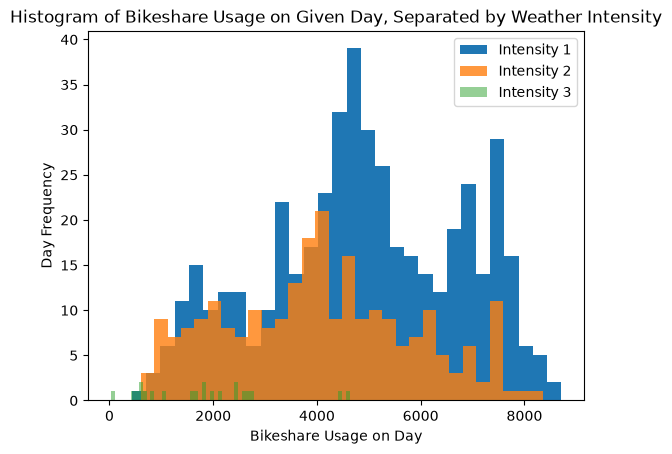

In [59]:
plt.hist(df_intens1, bins = 30)
plt.hist(df_intens2, bins = 30, alpha = 0.8)
plt.hist(df_intens3, bins = 60, alpha = 0.5)
plt.legend(["Intensity 1", "Intensity 2", "Intensity 3"])
plt.xlabel("Bikeshare Usage on Day")
plt.ylabel("Day Frequency")
plt.title("Histogram of Bikeshare Usage on Given Day, Separated by Weather Intensity")

Looking at the summary statistics and histogram, we probably won't get much out of copmaring Intensity 3 to the others, but we should compare Intensities 1-3 anyways. So, an ANOVA test would work pretty well here.

Let the significance level, $\alpha = 0.05$

$H_0$: The intensity of weather has no bearing on Bikeshare usage on a given day.

$H_A$: The intensity of weather has a bearing on Bikeshare usage on a given day.

In [73]:
f_oneway(df_intens1, df_intens2, df_intens3)

F_onewayResult(statistic=np.float64(40.06604492024683), pvalue=np.float64(3.1063172700532037e-17))

We very clearly see that there's a difference between some groups, because the p-value is significantly below our significance level. We can run a Tukey's HSD test to look at all types of groups.

In [74]:
print(tukey_hsd(df_intens1, df_intens2, df_intens3))

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)    840.924     0.000   500.217  1181.630
 (0 - 2)   3073.500     0.000  2108.755  4038.246
 (1 - 0)   -840.924     0.000 -1181.630  -500.217
 (1 - 2)   2232.577     0.000  1249.699  3215.454
 (2 - 0)  -3073.500     0.000 -4038.246 -2108.755
 (2 - 1)  -2232.577     0.000 -3215.454 -1249.699



Where 0 = Intensity 1, 1 = Intensity 2, 2 = Intensity 3. The most interesting statistic of note is the difference between group one and group two, where we still note a st

# Are there more registered bikers on working days?

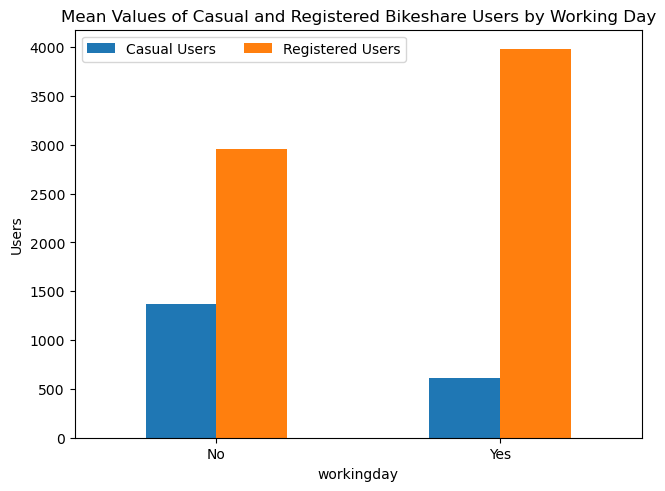

In [7]:
df_workday = df.groupby('workingday')[['casual','registered']].mean()
df_workday.columns = ['Casual Users', 'Registered Users']

fig, ax = plt.subplots(layout='constrained')
df_workday.plot(kind='bar', ax=ax, rot=0)
# Title and other labels

ax.set_ylabel('Users')
ax.set_title('Mean Values of Casual and Registered Bikeshare Users by Working Day')
ax.legend(loc='upper left', ncols=3)
ax.set_xticklabels(['No','Yes'])

plt.show()

This bar chart shows that while there are more registered Bikeshare users than casual ones, on average, the number of registered users is significantly higher and the number of casual users is lower on working days. This could mean that work travel is a notable reason for registering, and people tend to use Bikeshare casually in their free time outside of work.